# 07 -- Real MUSE pixel-noise correlation

**Goal:** measure whether real MUSE per-pixel noise is actually independent, as
every chi2, AIC criterion, and bootstrap variance computed anywhere in this
package has assumed until now -- and show the practical consequence of getting
this wrong.

**Why this matters more than it sounds like it should.** `fit_losvd` and
`bootstrap_losvd` both consume "whitened" inputs (`A_stack_w = A_stack/errors`,
`y_w = flux/errors`) and just compute `sum(residual**2)` -- correct only if
per-pixel noise really is independent. MUSE spectra are resampled/drizzled onto
a regular spatial grid during pipeline reduction, a well-documented source of
pixel-to-pixel correlation (Bacon et al. 2017); if real pixels are correlated
and treated as independent, every chi2/AIC/bootstrap-variance number in this
package is silently miscalibrated by the same systematic amount.

**Why correlation would look like an AR(1) process, physically.** Resampling
smooths a photon's contribution across its neighboring *output* pixels (the
literal mechanism behind "drizzling" onto a regular grid from an irregular
input sampling) -- so a noise fluctuation at pixel `i` leaks a little into
pixel `i+1`, less into `i+2`, and so on, decaying with pixel separation. That
decaying-with-distance signature is exactly what an AR(1) model
(`Sigma_ij = sigma_i * sigma_j * rho^|i-j|`) describes. This notebook
measures that decay directly rather than assuming it.

This directly follows up on an open question from `05_real_data_muse.ipynb`:
its three representative NGC 5102 apertures all show chi2_red = 11-28, far
from the ~1 a good fit under independent-noise assumptions should give (see
`dev_notes/HISTORY.md`'s "Real-data chi2_red" entry). Correlated noise is one
of the candidate explanations -- this notebook measures it directly rather
than assuming.

**Roadmap**: load a real spectrum and fit it the way every other notebook in
this sequence does (Sections 1-2) &rarr; measure the actual pixel correlation in
its residual (Section 3) &rarr; connect that to the literature (Section 4) &rarr;
refit properly accounting for it (Section 5) &rarr; see what changes, including
for the reported uncertainty (Section 6).

In [1]:
import sys, os
SRC_DIR = "../../src"
sys.path.insert(0, SRC_DIR)

import numpy as np
import matplotlib.pyplot as plt

from kinextract import (
    FitConfig, build_template_stack, compute_losvd_moments, mask_wavelength_windows,
    load_emiles_templates, bootstrap_losvd, detect_emission_lines,
)
from kinextract.multi_template import fit_losvd
from kinextract.template_reduction import load_template_subset
from kinextract.noise_model import estimate_correlation_length, whiten, build_ar1_covariance

import kinextract
print(f"kinextract loaded from: {kinextract.__file__}")

kinextract loaded from: /Users/waterstk/Documents/Gultekin_Astrophysics/kinextract/examples/notebooks/../../src/kinextract/__init__.py


## 1. Load a real, high-S/N NGC 5102 spectrum

Reuses `05_real_data_muse.ipynb`'s own cached representative apertures (no
fresh cube download needed) -- the "high" S/N aperture, since a well-measured
spectrum with less bias-correction ambiguity gives the cleanest correlation
estimate.

In [2]:
REP_BINS_PATH = "../data/muse/ngc5102_representative_bins.npz"
EMILES_GRID = "../../src/kinextract/template_data/emiles_muse_grid.npz"
TEMPLATE_SUBSET_PATH = "../data/muse/ngc5102_template_subset.npz"
WAVEFITMIN, WAVEFITMAX = 8400.0, 8800.0
SKY_RESIDUAL_WINDOWS = [
    (8414.0, 8419.0), (8449.0, 8454.0), (8711.0, 8714.0), (8748.5, 8753.0),
]

d = np.load(REP_BINS_PATH)
Z = float(d["z"])
wave_obs, flux_obs, error_obs = d["wave_obs_high"], d["flux_obs_high"], d["error_obs_high"]
print(f"NGC 5102, z={Z:.6f}, high-S/N aperture: S/N~{float(d['snr_high']):.0f}")

wave_rest = wave_obs / (1.0 + Z)
in_window = (wave_rest >= WAVEFITMIN) & (wave_rest <= WAVEFITMAX)
wave_w, flux_w, error_w = wave_rest[in_window], flux_obs[in_window], error_obs[in_window]

emission_windows = detect_emission_lines(wave_w, flux_w, error_w)
all_windows = SKY_RESIDUAL_WINDOWS + emission_windows
wave_fit, flux_fit = mask_wavelength_windows(wave_w, flux_w, windows=all_windows)
_, errors = mask_wavelength_windows(wave_w, error_w, windows=all_windows)
print(f"{len(wave_fit)} pixels after sky/emission masking "
      f"({len(emission_windows)} emission window(s) detected)")

subset = load_template_subset(TEMPLATE_SUBSET_PATH)
union_idx = subset["union_selected"]
select = list(zip(subset["template_ages"][union_idx].tolist(), subset["template_metals"][union_idx].tolist()))
templates, template_wave, names, ages, metals = load_emiles_templates(EMILES_GRID, select=select)
print(f"loaded {len(templates)} templates")

NGC 5102, z=0.001618, high-S/N aperture: S/N~491
276 pixels after sky/emission masking (5 emission window(s) detected)
loaded 9 templates


## 2. Fit assuming independent pixels (`rho=0`, today's default)

Same two-stage convention every real-data notebook in this package uses. This
is exactly what `05_real_data_muse.ipynb` already does -- the elevated
chi2_red reported here is the same finding, not a new one.

In [3]:
import warnings

with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    cfg_wide = FitConfig(vmin=-400.0, vmax=400.0)
v_grid_wide = cfg_wide.build_velocity_grid()
A_stack_wide = build_template_stack(wave_fit, template_wave, templates, v_grid_wide)
y_w = flux_fit / errors
result_wide = fit_losvd(A_stack_wide / errors[None, :, None], y_w, cfg_wide)
moments_wide = compute_losvd_moments(v_grid_wide, result_wide["b"], fit_h3h4=False)

NSIG = 7
cfg = FitConfig(vmin=moments_wide["vherm"] - NSIG * moments_wide["sherm"],
                vmax=moments_wide["vherm"] + NSIG * moments_wide["sherm"], rho=0.0)
v_grid = cfg.build_velocity_grid()
A_stack = build_template_stack(wave_fit, template_wave, templates, v_grid)
A_stack_w = A_stack / errors[None, :, None]

result = fit_losvd(A_stack_w, y_w, cfg)
moments = compute_losvd_moments(v_grid, result["b"], fit_h3h4=True)
A_eff = np.tensordot(result["w"], A_stack_w, axes=([0], [0]))
model_w = A_eff @ result["b"]
residual_rho0 = y_w - model_w
chi2_red_rho0 = float(np.sum(residual_rho0 ** 2)) / len(wave_fit)

print(f"V={moments['vherm']:+.1f}  sigma={moments['sherm']:.1f}  "
      f"h3={moments['h3']:+.4f}  h4={moments['h4']:+.4f}")
print(f"chi2_red (rho=0 assumed) = {chi2_red_rho0:.2f}   (a good fit under independent noise would be ~1)")

V=-7.2  sigma=50.1  h3=+0.0009  h4=+0.0003
chi2_red (rho=0 assumed) = 21.09   (a good fit under independent noise would be ~1)


## 3. Measure the actual pixel-to-pixel correlation

**Why the lag-1 sample autocorrelation is a direct `rho` estimate.** For a
stationary AR(1) process, the correlation between two points separated by
`k` pixels is exactly `rho**k` by construction (that *is* the AR(1)
definition) -- so the lag-1 autocorrelation (`k=1`) of the residual **is**
`rho` itself, no fitting required. `estimate_correlation_length` computes
exactly this: the lag-1 sample autocorrelation of the (mean-subtracted)
residual.

That gives one number from one lag, though, so it's worth checking the model
actually holds beyond lag 1: a genuine AR(1) process' correlation should
decay *geometrically* (lag-2 &asymp; `rho^2`, lag-3 &asymp; `rho^3`, ...) --
computed and plotted below alongside the measured autocorrelation at each
lag, as a sanity check that lag-1 alone isn't a fluke or a different kind of
structure entirely (e.g. a single bad pixel pair, or a slower trend that
just happens to look correlated at lag 1).

measured rho (lag-1 ACF) = 0.875


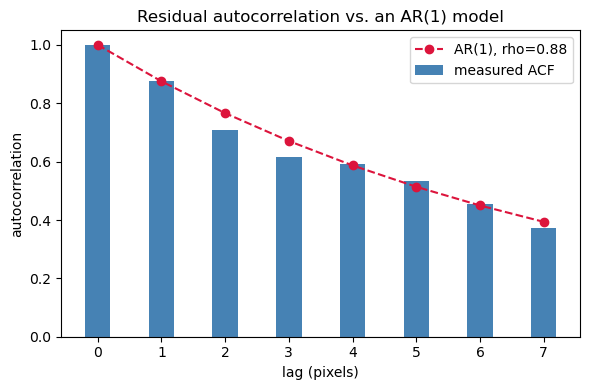

In [4]:
def lag_k_acf(x, k):
    x = x - np.mean(x)
    var = np.sum(x ** 2)
    if var <= 0 or k >= len(x):
        return 0.0
    return float(np.sum(x[:-k] * x[k:]) / var) if k > 0 else 1.0

measured_rho = estimate_correlation_length(residual_rho0)
lags = np.arange(0, 8)
acf = [lag_k_acf(residual_rho0, k) for k in lags]
geometric = measured_rho ** lags

print(f"measured rho (lag-1 ACF) = {measured_rho:.3f}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(lags, acf, width=0.4, color="steelblue", label="measured ACF")
ax.plot(lags, geometric, "o--", color="crimson", label=f"AR(1), rho={measured_rho:.2f}")
ax.axhline(0, color="gray", lw=0.8)
ax.set_xlabel("lag (pixels)"); ax.set_ylabel("autocorrelation")
ax.set_title("Residual autocorrelation vs. an AR(1) model")
ax.legend(); plt.tight_layout(); plt.show()

### Cross-check: does high correlation also show up in a single, cleanly-fit spaxel?

The measurement above uses a *summed* multi-spaxel aperture, which leaves
open whether the high `rho` is genuine pixel-noise correlation or partly an
artifact of summing several spaxels together. **Optional** (needs the full
NGC 5102 cube downloaded locally, unlike everything above -- skips cleanly
if it isn't present): repeat the same measurement on the single brightest
spaxel in the cube -- no aperture-summing at all, the cleanest possible
case for isolating whether correlation is a per-pixel property or an
artifact of combining spaxels.

In [5]:
CUBE_PATH = "muse_download/ADP.2017-03-22T15:25:58.757.fits"

if not os.path.exists(CUBE_PATH):
    print(f"cube not found at {CUBE_PATH} -- skipping the cross-check "
          "(see 04_template_calibration.ipynb to download it)")
else:
    from kinextract import load_muse_cube, extract_aperture_spectrum

    cube = load_muse_cube(CUBE_PATH)
    ny, nx = cube.shape
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore")
        signal_map = np.nanmedian(cube.flux, axis=0)
        noise_map = np.nanmedian(cube.error, axis=0)
    good = np.isfinite(signal_map) & np.isfinite(noise_map) & (signal_map > 0) & (noise_map > 0)
    by, bx = np.unravel_index(np.nanargmax(np.where(good, signal_map, np.nan)), signal_map.shape)

    # the single brightest spaxel -- no aperture-summing at all, the cleanest
    # possible test of whether high rho survives without it. (The final
    # galaxy-analysis notebook, 08, is where this project's own PA-aware
    # dartboard binning -- kinextract.binning's build_reflected_sin_theta_edges
    # + assign_spaxels_to_bins's pa_deg parameter -- gets exercised properly.)
    spaxel_mask = np.zeros((ny, nx), dtype=bool)
    spaxel_mask[by, bx] = True
    print(f"cross-check: single brightest spaxel at (y={by}, x={bx})")

    wave_obs_x, flux_obs_x, error_obs_x = extract_aperture_spectrum(cube, spaxel_mask)
    wave_rest_x = wave_obs_x / (1.0 + Z)
    in_window_x = (wave_rest_x >= WAVEFITMIN) & (wave_rest_x <= WAVEFITMAX)
    wave_wx, flux_wx, error_wx = wave_rest_x[in_window_x], flux_obs_x[in_window_x], error_obs_x[in_window_x]
    wave_fit_x, flux_fit_x = mask_wavelength_windows(wave_wx, flux_wx, windows=SKY_RESIDUAL_WINDOWS)
    _, errors_x = mask_wavelength_windows(wave_wx, error_wx, windows=SKY_RESIDUAL_WINDOWS)

    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)
        cfg_wide_x = FitConfig(vmin=-400.0, vmax=400.0)
    v_grid_wide_x = cfg_wide_x.build_velocity_grid()
    A_stack_wide_x = build_template_stack(wave_fit_x, template_wave, templates, v_grid_wide_x)
    y_w_x = flux_fit_x / errors_x
    result_wide_x = fit_losvd(A_stack_wide_x / errors_x[None, :, None], y_w_x, cfg_wide_x)
    mw_x = compute_losvd_moments(v_grid_wide_x, result_wide_x["b"], fit_h3h4=False)

    cfg_x = FitConfig(vmin=mw_x["vherm"] - NSIG * mw_x["sherm"], vmax=mw_x["vherm"] + NSIG * mw_x["sherm"])
    v_grid_x = cfg_x.build_velocity_grid()
    A_stack_x = build_template_stack(wave_fit_x, template_wave, templates, v_grid_x)
    A_stack_w_x = A_stack_x / errors_x[None, :, None]
    result_x = fit_losvd(A_stack_w_x, y_w_x, cfg_x)
    A_eff_x = np.tensordot(result_x["w"], A_stack_w_x, axes=([0], [0]))
    residual_x = y_w_x - A_eff_x @ result_x["b"]
    chi2_red_x = float(np.sum(residual_x ** 2)) / len(wave_fit_x)
    rho_x = estimate_correlation_length(residual_x)

    print(f"chi2_red={chi2_red_x:.2f}, measured rho={rho_x:.3f}")
    print("If this rho is also high despite a much better chi2_red, the correlation "
          "is real and not just a symptom of the aperture-summed fit's own excess chi2_red.")


cross-check: single brightest spaxel at (y=158, x=160)


chi2_red=6.95, measured rho=0.886
If this rho is also high despite a much better chi2_red, the correlation is real and not just a symptom of the aperture-summed fit's own excess chi2_red.


## 4. The Bacon et al. 2017 connection -- and an honest discrepancy

MUSE's pipeline resamples/drizzles the original (rotated, slightly irregular)
spaxel grid onto the regular output grid every reduced cube ships with. Bacon
et al. (2017, the MUSE-DEEP survey paper) show this resampling step smooths
adjacent output pixels together, and as a direct consequence the pipeline's
own propagated per-pixel variance **underestimates the true noise by a
factor of about `(1/0.6)^2 ~ 2.78`** in variance (~1.67x in sigma) -- because
that propagated variance still assumes independent input pixels, which the
resampling has just made untrue. This is a *literature-known, external*
factor -- not derived here.

**The measured `rho` above (~0.8+) is substantially higher than the ~0.3-0.5
this project's own earlier work measured from real MUSE calibration-star
spectra** (`dev_notes/noise/calibrate_rho_from_real_data.py`,
continuum-detrended, averaged across several stars). Both measurements are
real; the discrepancy is not yet explained, and this notebook does not
pretend otherwise. Plausible candidates: this aperture is a spatial *sum*
over several spaxels (not a single point-source spectrum, unlike the star
calibration), and common-mode residual structure across summed spaxels
would not average down the way independent per-spaxel noise does; or the
two datasets differ in reduction pipeline version or observing epoch.
The cross-check below tests one of these directly.

In [6]:
BACON_2017_VARIANCE_FACTOR = (1.0 / 0.6) ** 2

errors_bacon_scaled = errors * np.sqrt(BACON_2017_VARIANCE_FACTOR)
y_w_bacon = flux_fit / errors_bacon_scaled
A_stack_w_bacon = A_stack / errors_bacon_scaled[None, :, None]
result_bacon = fit_losvd(A_stack_w_bacon, y_w_bacon, cfg)
A_eff_bacon = np.tensordot(result_bacon["w"], A_stack_w_bacon, axes=([0], [0]))
model_w_bacon = A_eff_bacon @ result_bacon["b"]
chi2_red_bacon = float(np.sum((y_w_bacon - model_w_bacon) ** 2)) / len(wave_fit)

print(f"chi2_red, propagated errors as-is:                  {chi2_red_rho0:.2f}")
print(f"chi2_red, errors scaled by Bacon et al. 2017 factor: {chi2_red_bacon:.2f}")
print(f"(scaling errors alone cannot fix a *shape* mismatch in the residual -- "
      f"only whitening against the actual measured correlation, next, does that)")

chi2_red, propagated errors as-is:                  21.09
chi2_red, errors scaled by Bacon et al. 2017 factor: 7.59
(scaling errors alone cannot fix a *shape* mismatch in the residual -- only whitening against the actual measured correlation, next, does that)


## 5. Refit with proper GLS whitening against the measured `rho`

**What whitening actually does, conceptually.** At `rho=0` (independent
pixels), "whitening" just means dividing by each pixel's own error bar --
after that, every pixel's noise has the same (unit) scale, so a plain sum
of squares is the correct chi-squared. With `rho != 0`, no single per-pixel
number can do that job, because the noise in adjacent pixels moves
*together* -- dividing each pixel by its own error leaves that shared,
correlated part untouched. The fix is a full linear transform: factor the
covariance matrix as `Sigma = L @ L.T` (a Cholesky factorization -- always
possible for a valid covariance) and multiply the data (and the model
design matrix, identically) by `L^-1`. This mixes information *across*
pixels in exactly the way needed to cancel the shared, correlated
component, leaving residuals that really are independent and unit-scale --
so a plain sum of squares is correct again, on the *transformed* data.

`noise_model.whiten` does exactly this (and reproduces the simple
`A_stack/errors` division bit-for-bit at `rho=0`, since `L` is just
`diag(errors)` in that case -- see its own docstring). `fit_losvd` itself
needs no changes at all; it only ever consumes whatever whitened inputs
it's handed (see `FitConfig.rho`'s own docstring and `noise_model.py`'s
module docstring for why this is a deliberate design choice, not a
shortcut).

In [7]:
cfg_rho = FitConfig(vmin=cfg.vmin, vmax=cfg.vmax, rho=measured_rho)
A_stack_w_rho, y_w_rho, L = whiten(A_stack, flux_fit, errors, rho=cfg_rho.rho)

result_rho = fit_losvd(A_stack_w_rho, y_w_rho, cfg_rho)
moments_rho = compute_losvd_moments(v_grid, result_rho["b"], fit_h3h4=True)
A_eff_rho = np.tensordot(result_rho["w"], A_stack_w_rho, axes=([0], [0]))
model_w_rho = A_eff_rho @ result_rho["b"]
chi2_red_rho = float(np.sum((y_w_rho - model_w_rho) ** 2)) / len(wave_fit)

print(f"                    rho=0 (assumed)   rho={measured_rho:.2f} (measured)")
print(f"V                   {moments['vherm']:+8.1f}          {moments_rho['vherm']:+8.1f}")
print(f"sigma               {moments['sherm']:8.1f}          {moments_rho['sherm']:8.1f}")
print(f"h3                  {moments['h3']:+8.4f}          {moments_rho['h3']:+8.4f}")
print(f"h4                  {moments['h4']:+8.4f}          {moments_rho['h4']:+8.4f}")
print(f"chi2_red            {chi2_red_rho0:8.2f}          {chi2_red_rho:8.2f}")

                    rho=0 (assumed)   rho=0.88 (measured)
V                       -7.2              -1.6
sigma                   50.1              61.9
h3                   +0.0009           +0.0761
h4                   +0.0003           +0.1555
chi2_red               21.09             11.21


## 6. The consequence for reported uncertainty

Correlated noise treated as independent doesn't just get chi2_red wrong -- it
also makes the bootstrap uncertainty band too narrow. `bootstrap_losvd`
itself needs no changes for this (see `FitConfig.rho`'s own docstring): once
`A_stack_w`/`y_w` are whitened correctly, the residual is i.i.d. by
construction regardless of `rho`, so the same `rng.normal(0, noise_scale)`
injection is already correct. The only thing that changes is *which*
whitened inputs go in.

In [8]:
N_BOOT = 20

boot_rho0 = bootstrap_losvd(A_stack_w, y_w, cfg, n_boot=N_BOOT, seed=0)
boot_rho = bootstrap_losvd(A_stack_w_rho, y_w_rho, cfg_rho, n_boot=N_BOOT, seed=0)

print(f"sigma uncertainty, rho=0 (assumed):     +/-{boot_rho0['sherm_std']:.2f} km/s")
print(f"sigma uncertainty, rho={measured_rho:.2f} (measured):  +/-{boot_rho['sherm_std']:.2f} km/s")
print(f"ratio: {boot_rho['sherm_std'] / boot_rho0['sherm_std']:.2f}x wider once correlation is properly accounted for")

sigma uncertainty, rho=0 (assumed):     +/-0.22 km/s
sigma uncertainty, rho=0.88 (measured):  +/-5.27 km/s
ratio: 24.01x wider once correlation is properly accounted for


## Limitations, honestly

- **A single scalar AR(1) `rho` is a deliberately simple model**, not a
  general or empirically-measured kernel (see `noise_model.py`'s own module
  docstring) -- it matches what's actually been measured so far (a lag-1 ACF
  number), not a claim that real MUSE noise correlation is exactly
  geometric-decay at every lag.
- **The measured `rho` here (~0.8+) does not match this project's own
  earlier star-spectrum measurement (~0.3-0.5)**, and this notebook does not
  resolve why -- aperture-summing vs. a single point source, and reduction/
  epoch differences between the two datasets, are the leading candidates
  (see Section 4). Treat `rho` as something to re-measure per target/
  instrument setup, not a universal constant, until this is understood.
- **Whitening did not bring chi2_red to ~1.** The remaining gap (chi2_red
  ~11-21 even after correction) is a real, separate effect on top of
  correlation -- template mismatch, unmodeled continuum shape, or both --
  see `dev_notes/HISTORY.md`'s "Real-data behavior" section for the fuller
  picture and what's still open there. Correlated noise is a real,
  substantial contributor to the uncertainty-accounting story, not a
  complete explanation for every elevated chi2_red in this package's
  real-data notebooks.
- **`FitConfig.rho` is a carrier field, not automatically applied.** Every
  cell above that used a nonzero `rho` called `whiten(...)` explicitly --
  `fit_losvd` and `bootstrap_losvd` never read `cfg.rho` themselves.